# Top-K activating images for SAE neurons

For every SAE neuron kept after pruning, we show the K training images that activate it most strongly.

- The **heatmap** projects the backbone's last feature map (`layer4`, 7×7) onto the neuron's decoder direction. Bright regions are where the neuron's direction is present; everything else is dimmed.
- Under each image: its class and the neuron's activation value.
- The bar chart shows which classes dominate the top activations. A neuron spread over many classes is more likely a shared visual concept; one dominated by a single class may just be a class detector.

Run the pipeline first (see `README.md`). By default this notebook uses the most recent SAE run in `outputs/sae/`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'

import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import Image, display

from concept_learning.topk import NeuronExplorer, latest_run

SAE_DIR = latest_run("sae")
explorer = NeuronExplorer(SAE_DIR)
print(f"SAE run: {SAE_DIR.name}")
print(f"Backbone: {explorer.activation_info['backbone']}")

SAE run: sae_resnet18_cub_20261118_164328
Backbone: resnet18_cub


## Run summary

In [2]:
m = explorer.metrics
p = m["pruning"]
summary = {
    "classifier accuracy (train / val / test)": " / ".join(f"{explorer.activation_info['classifier_accuracy'][s]:.2%}" for s in ["train", "val", "test"]),
    "SAE neurons": m["n_neurons"],
    "kept after pruning": p["kept_neurons"],
    "val reconstruction MSE": f"{m['val_reconstruction_loss']:.5f}",
    "val avg L0 (active neurons per image)": f"{m['val_avg_l0']:.2f}",
    "recovered accuracy, all neurons": f"{p['baseline_recovered_accuracy']:.2%}",
    "recovered accuracy, kept neurons": f"{p['selected_recovered_accuracy']:.2%}",
}
for key, value in summary.items():
    print(f"{key:>42}: {value}")

  classifier accuracy (train / val / test): 99.87% / 73.83% / 72.23%
                               SAE neurons: 512
                        kept after pruning: 417
                    val reconstruction MSE: 0.13952
     val avg L0 (active neurons per image): 43.40
           recovered accuracy, all neurons: 92.73%
          recovered accuracy, kept neurons: 91.59%


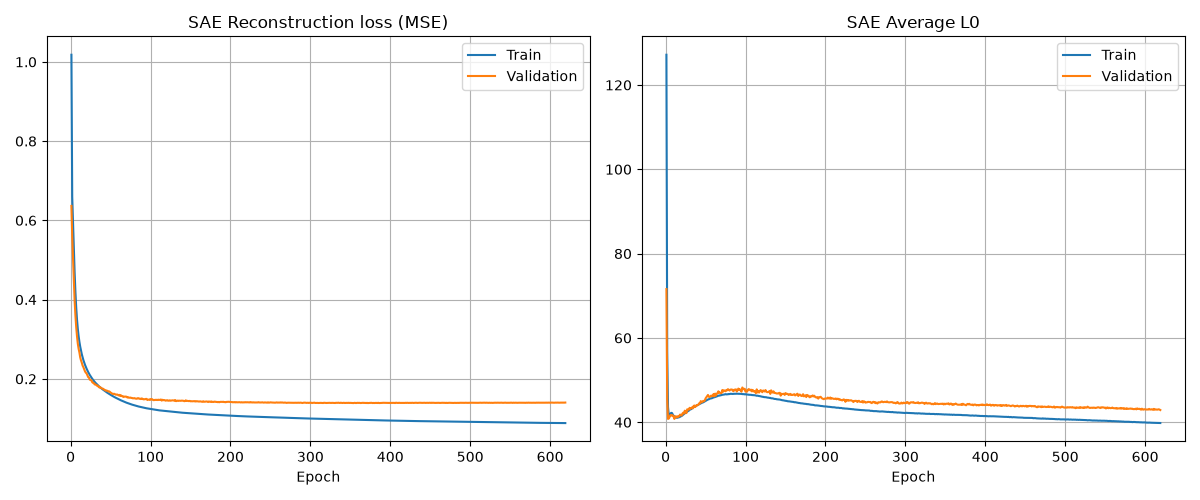

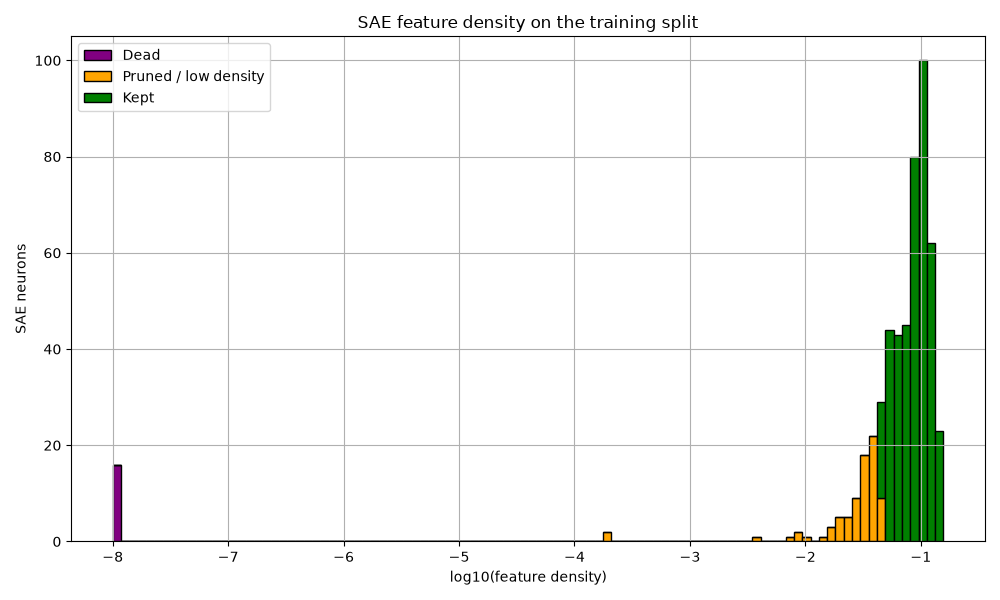

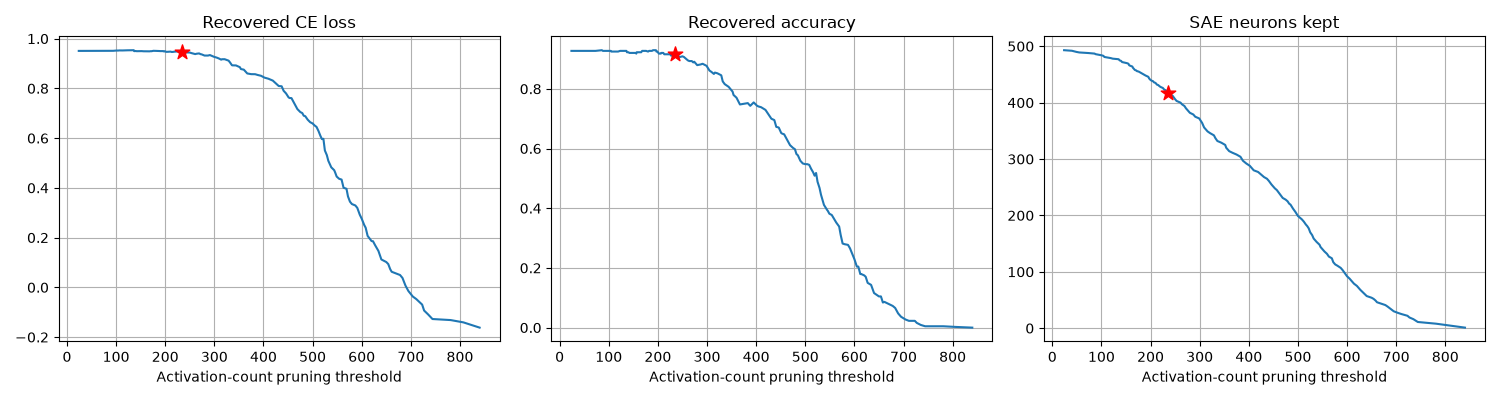

In [3]:
for plot in ["training_curves", "feature_density", "pruning_curve"]:
    display(Image(filename=SAE_DIR / "plots" / f"{plot}.png", width=900))

## Browse SAE neurons

Interactive picker. It only works in a live kernel; GitHub doesn't render widgets, so the static gallery below is what shows up in the committed notebook.

In [4]:
neuron_picker = widgets.Dropdown(
    options=[(f"neuron {u} (fires on {int(explorer.neuron_counts[u])} images)", u) for u in explorer.neurons_by_frequency()],
    description="Neuron",
    layout=widgets.Layout(width="420px"),
)
k_slider = widgets.IntSlider(value=10, min=5, max=30, step=5, description="K")
heatmap_toggle = widgets.Checkbox(value=True, description="Heatmap")


def show(neuron, k, heatmap):
    explorer.plot_neuron(neuron, k=k, heatmap=heatmap)
    plt.show()


output = widgets.interactive_output(show, {"neuron": neuron_picker, "k": k_slider, "heatmap": heatmap_toggle})
display(widgets.HBox([neuron_picker, k_slider, heatmap_toggle]), output)

Output()

## Static gallery

The `N_NEURONS` most frequently firing kept neurons, plus a random sample of the rest, so rarer (often more specific) neurons get shown too.

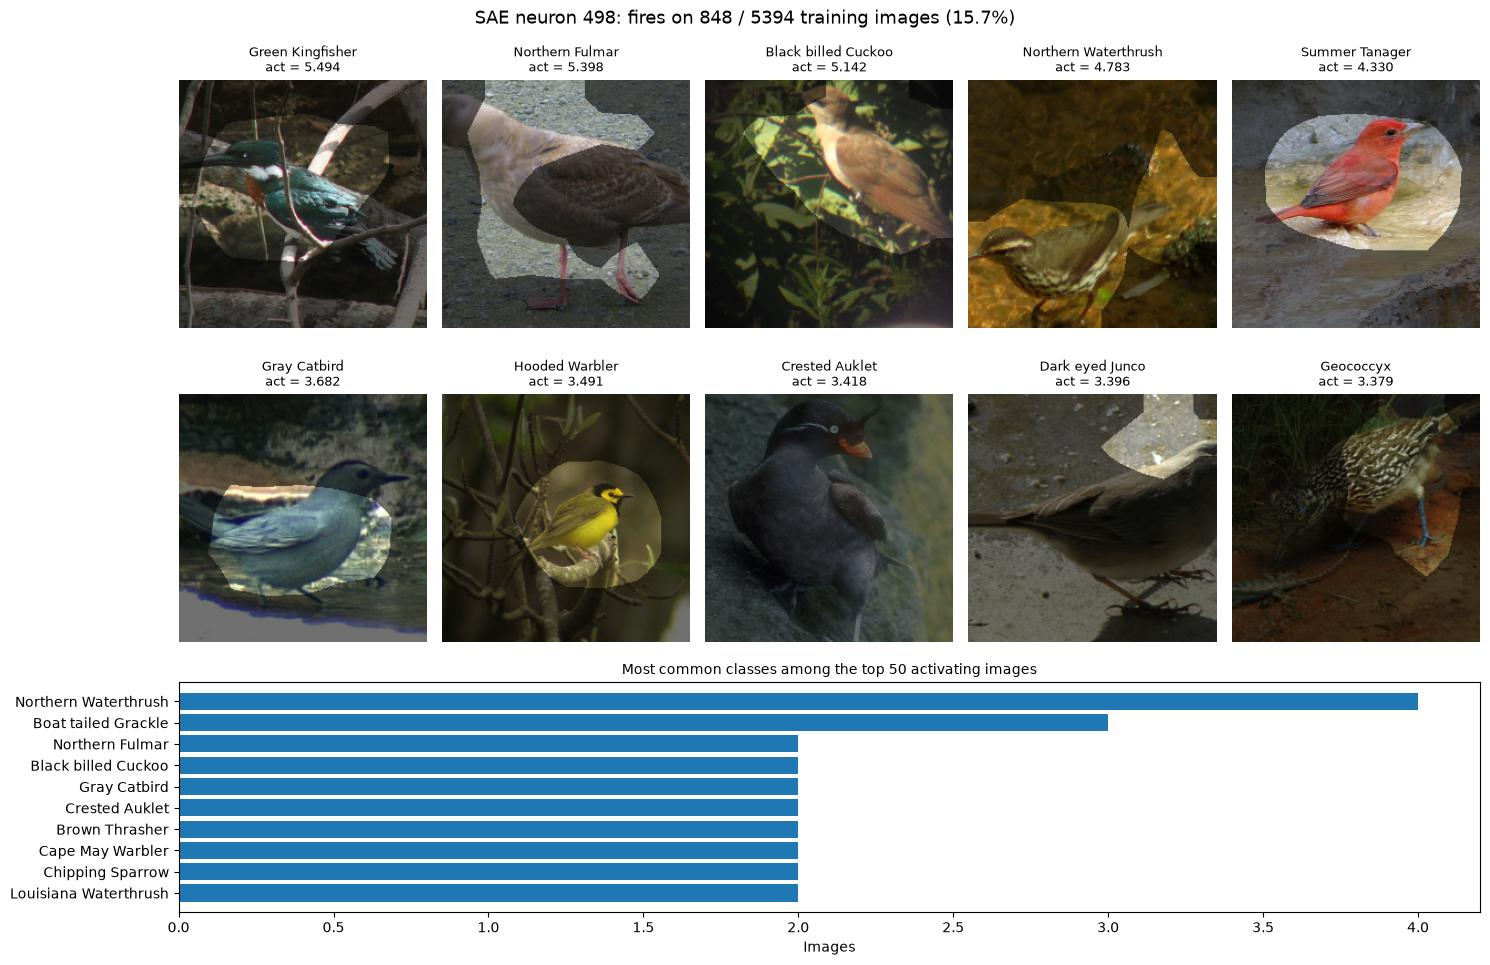

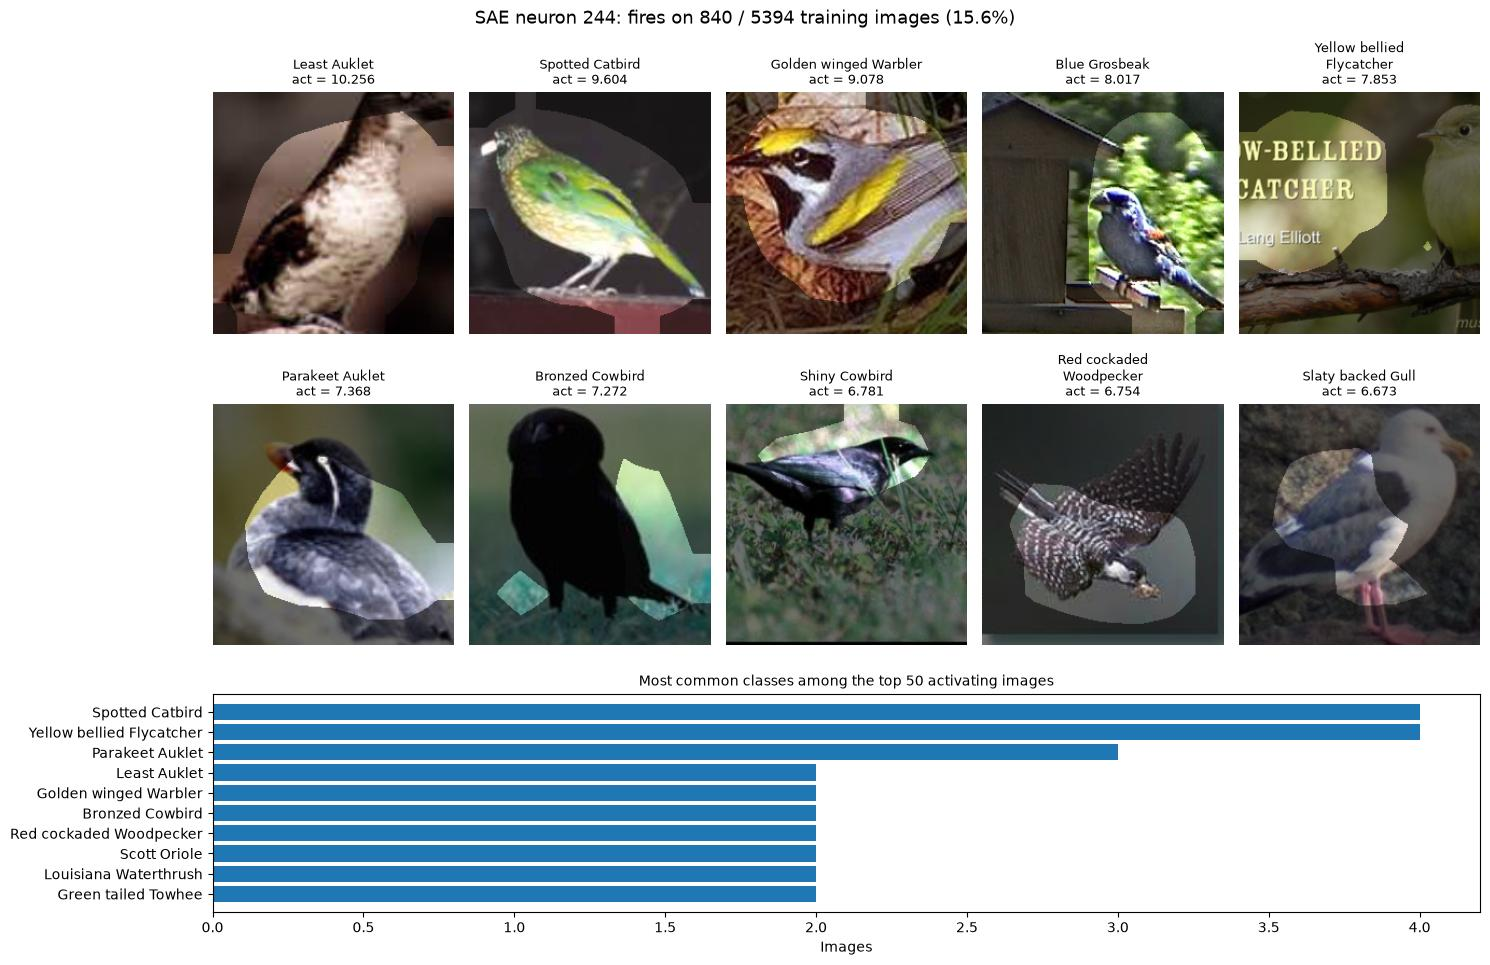

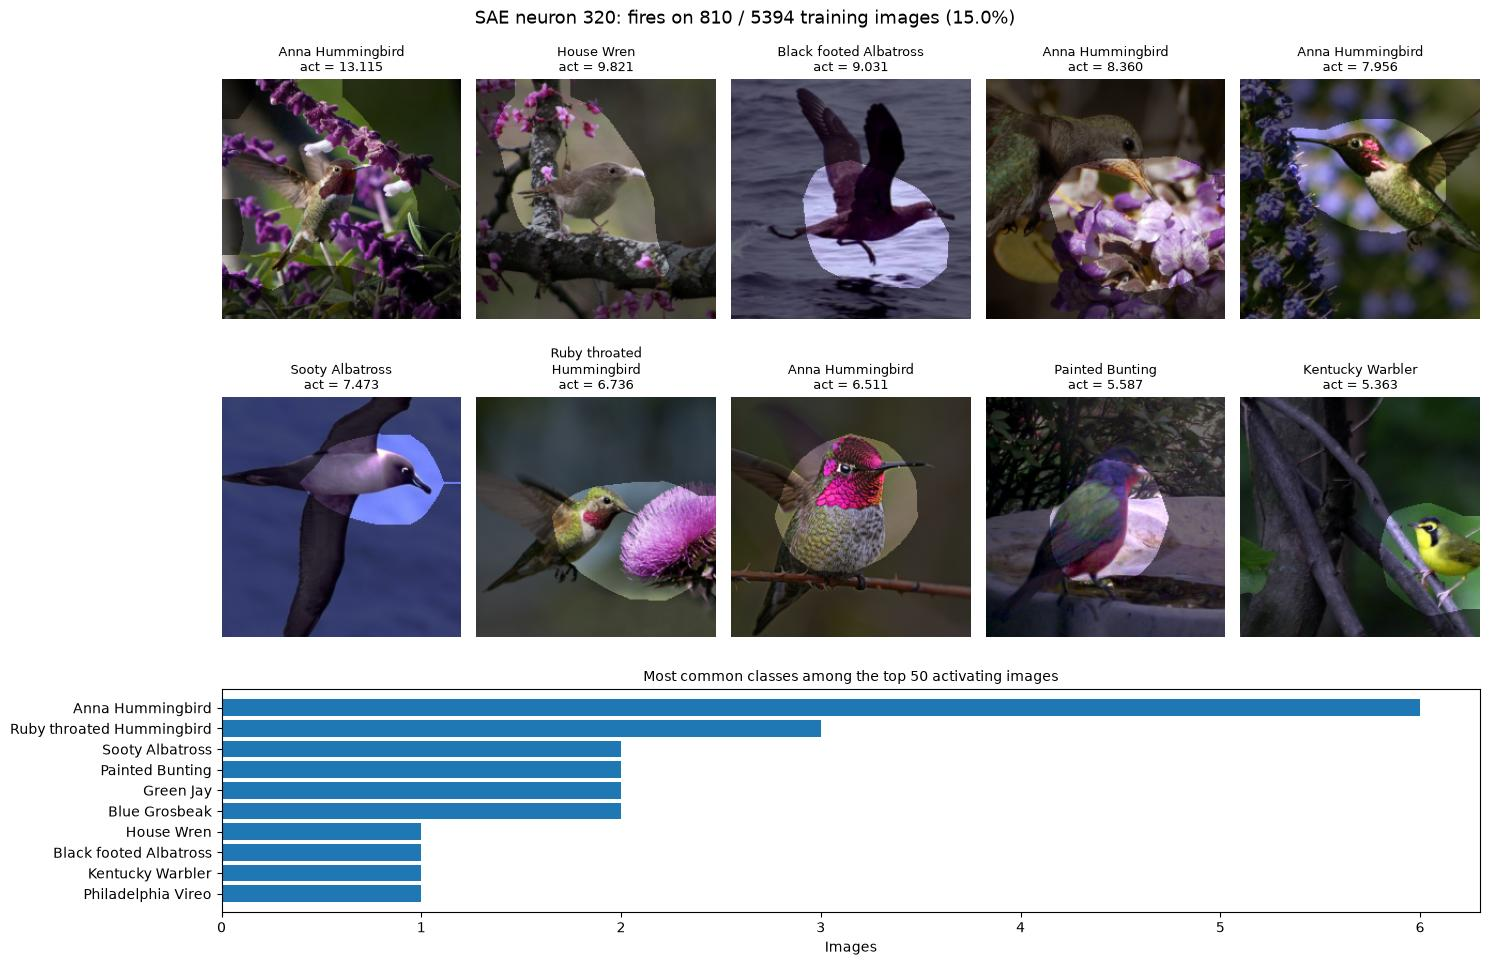

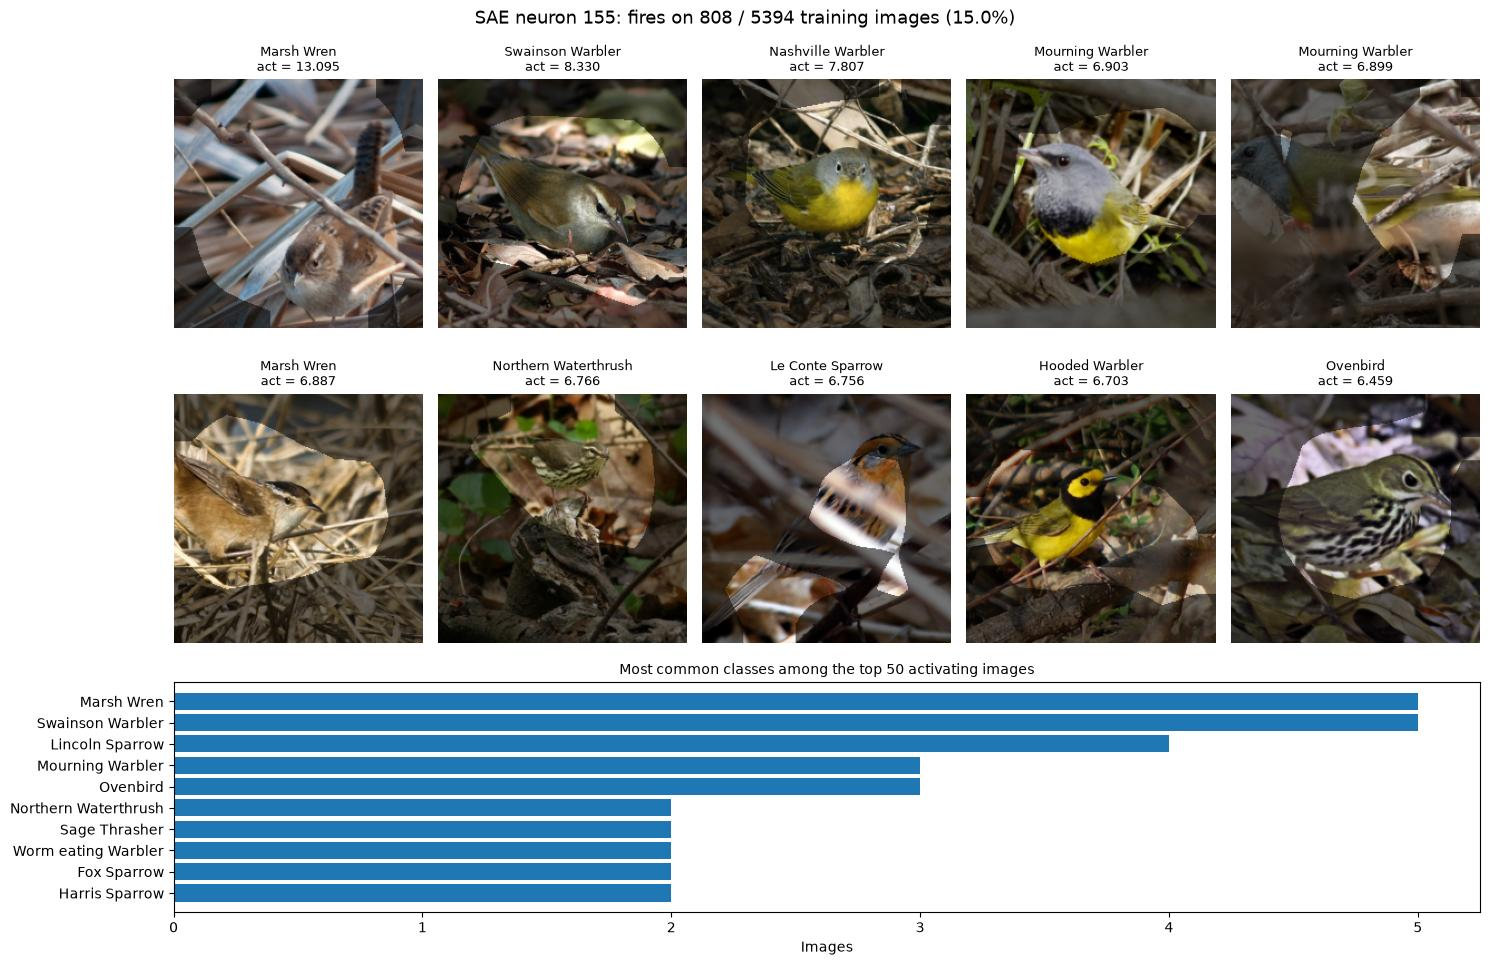

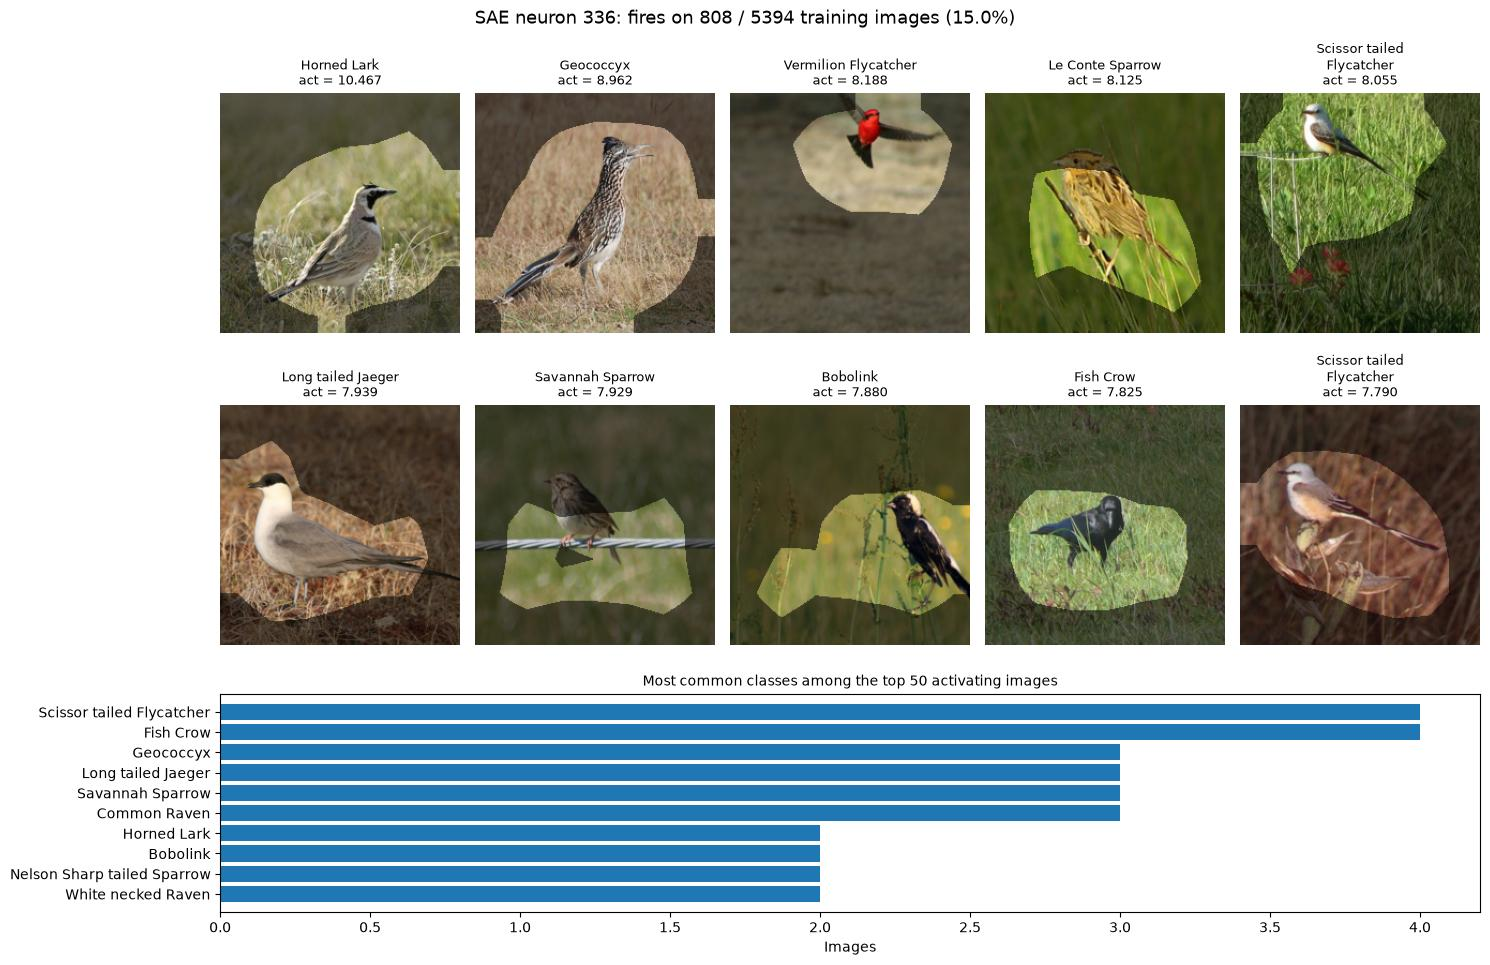

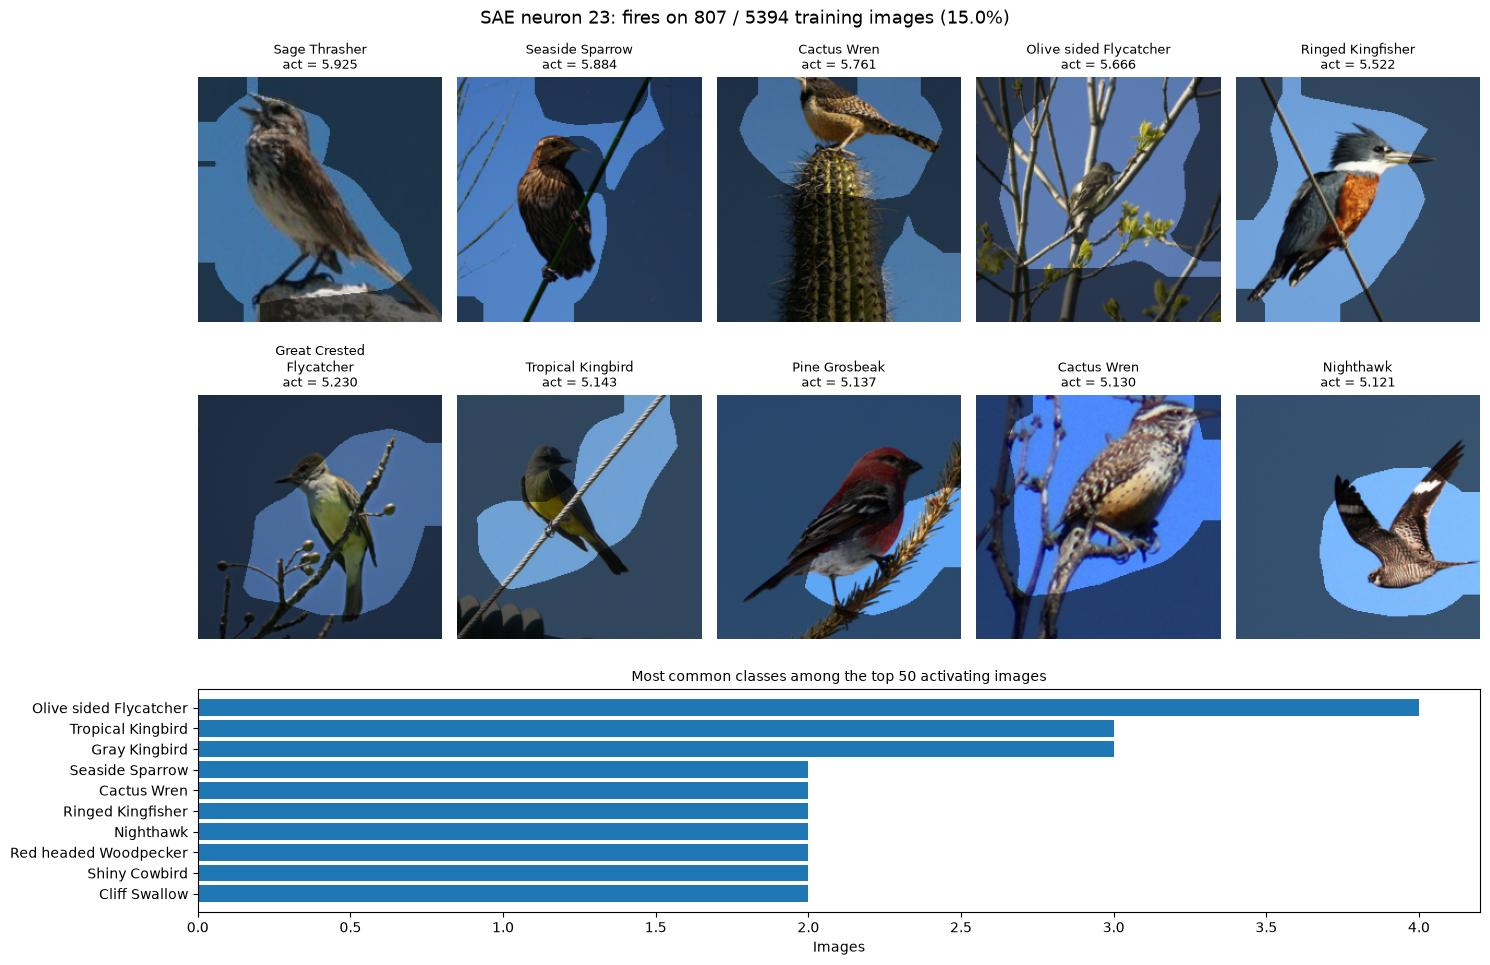

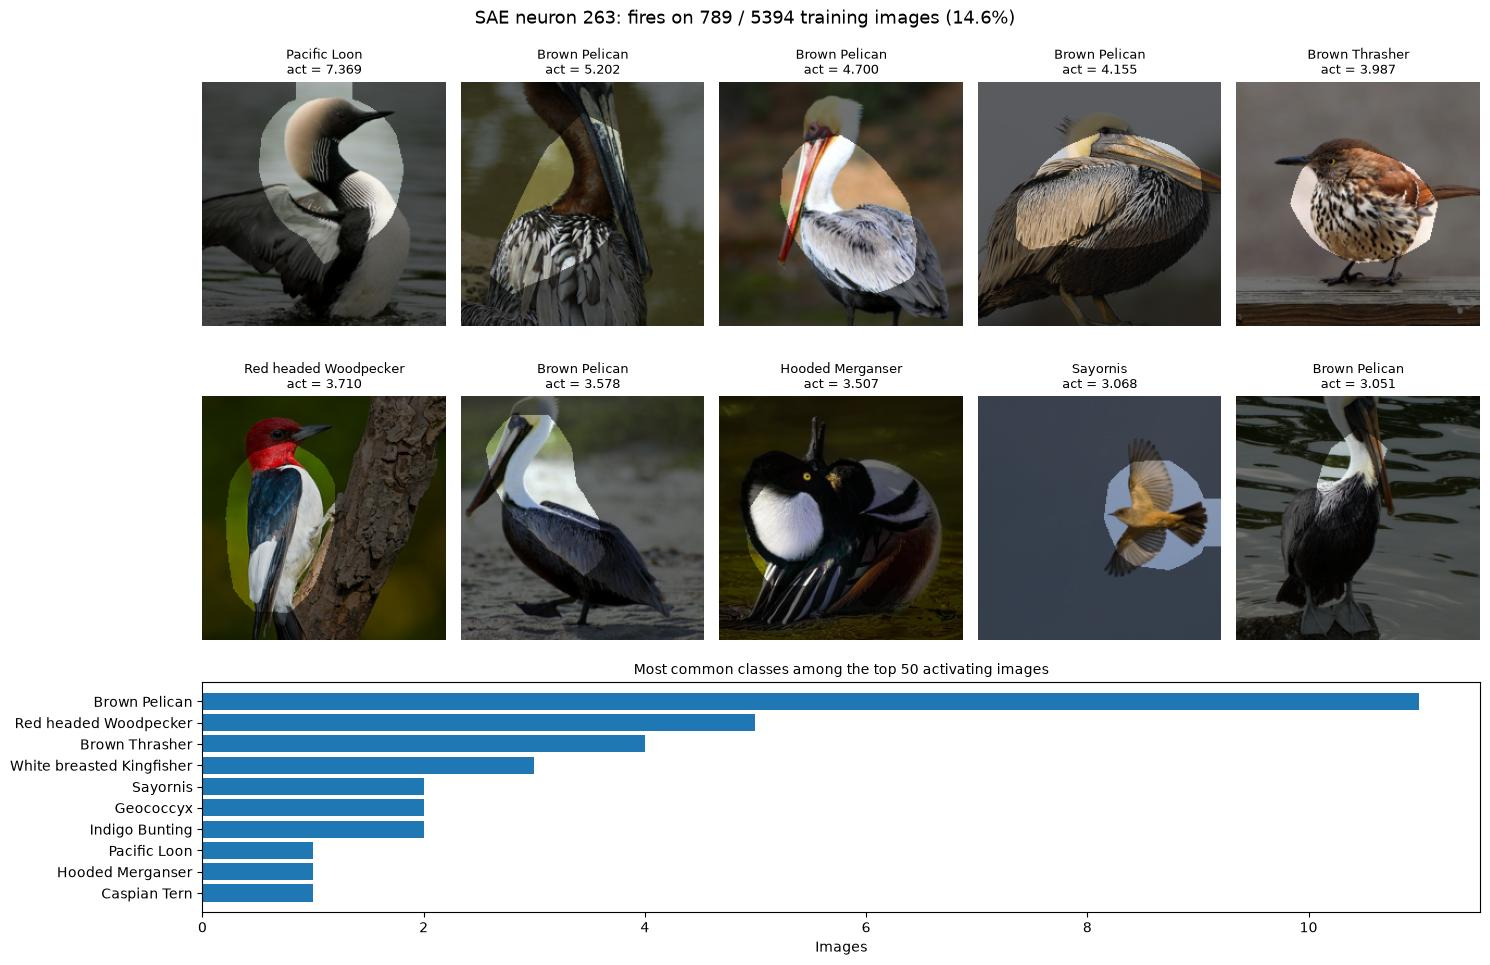

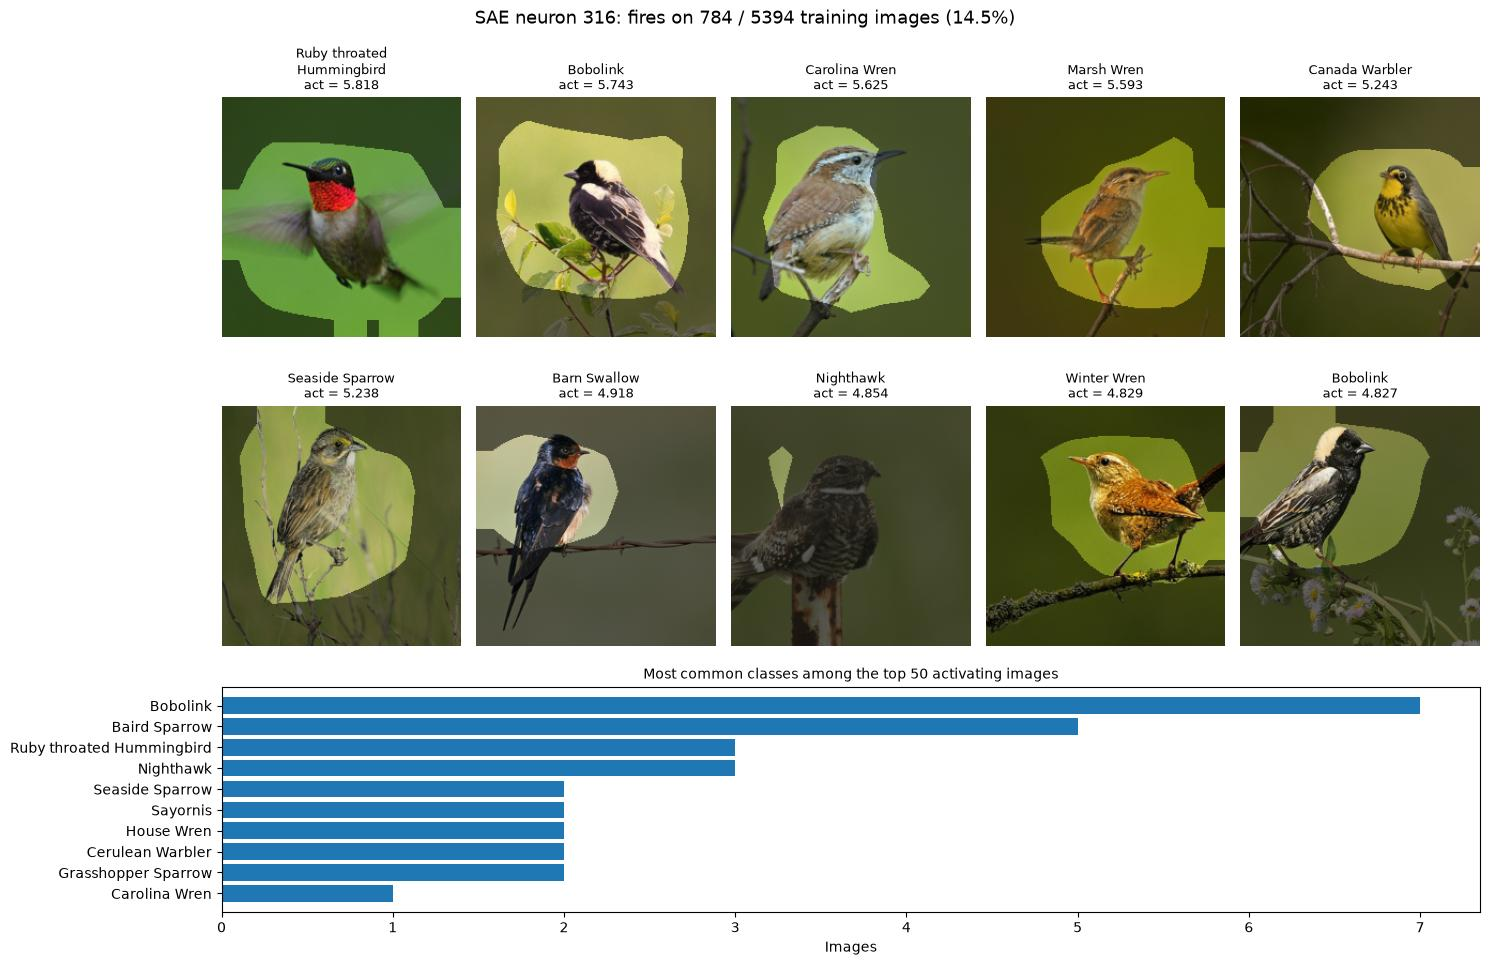

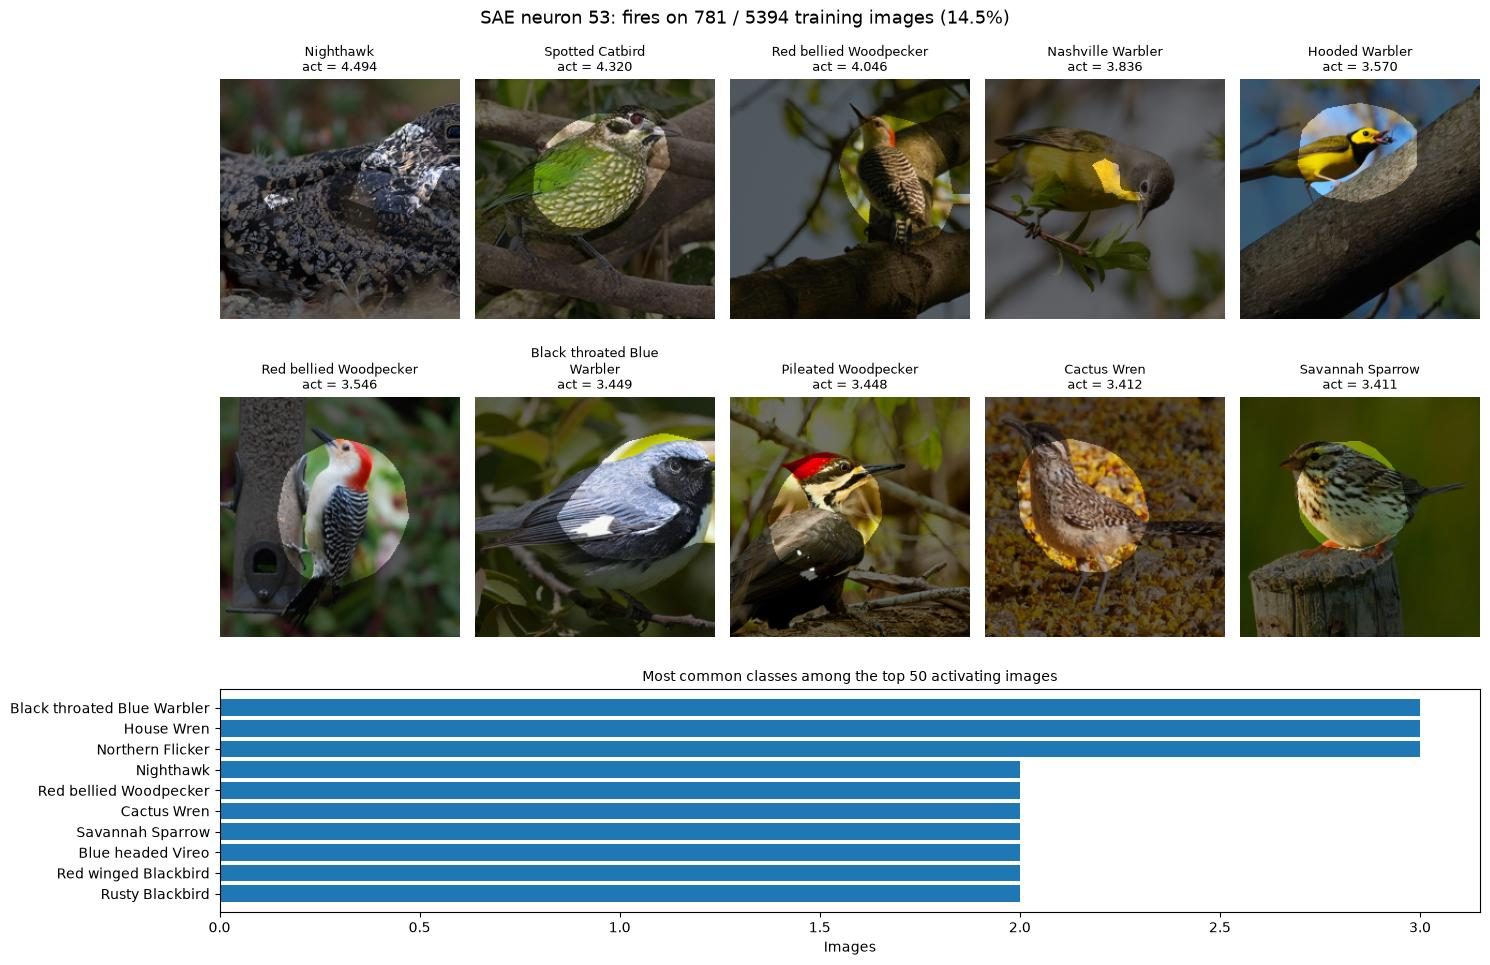

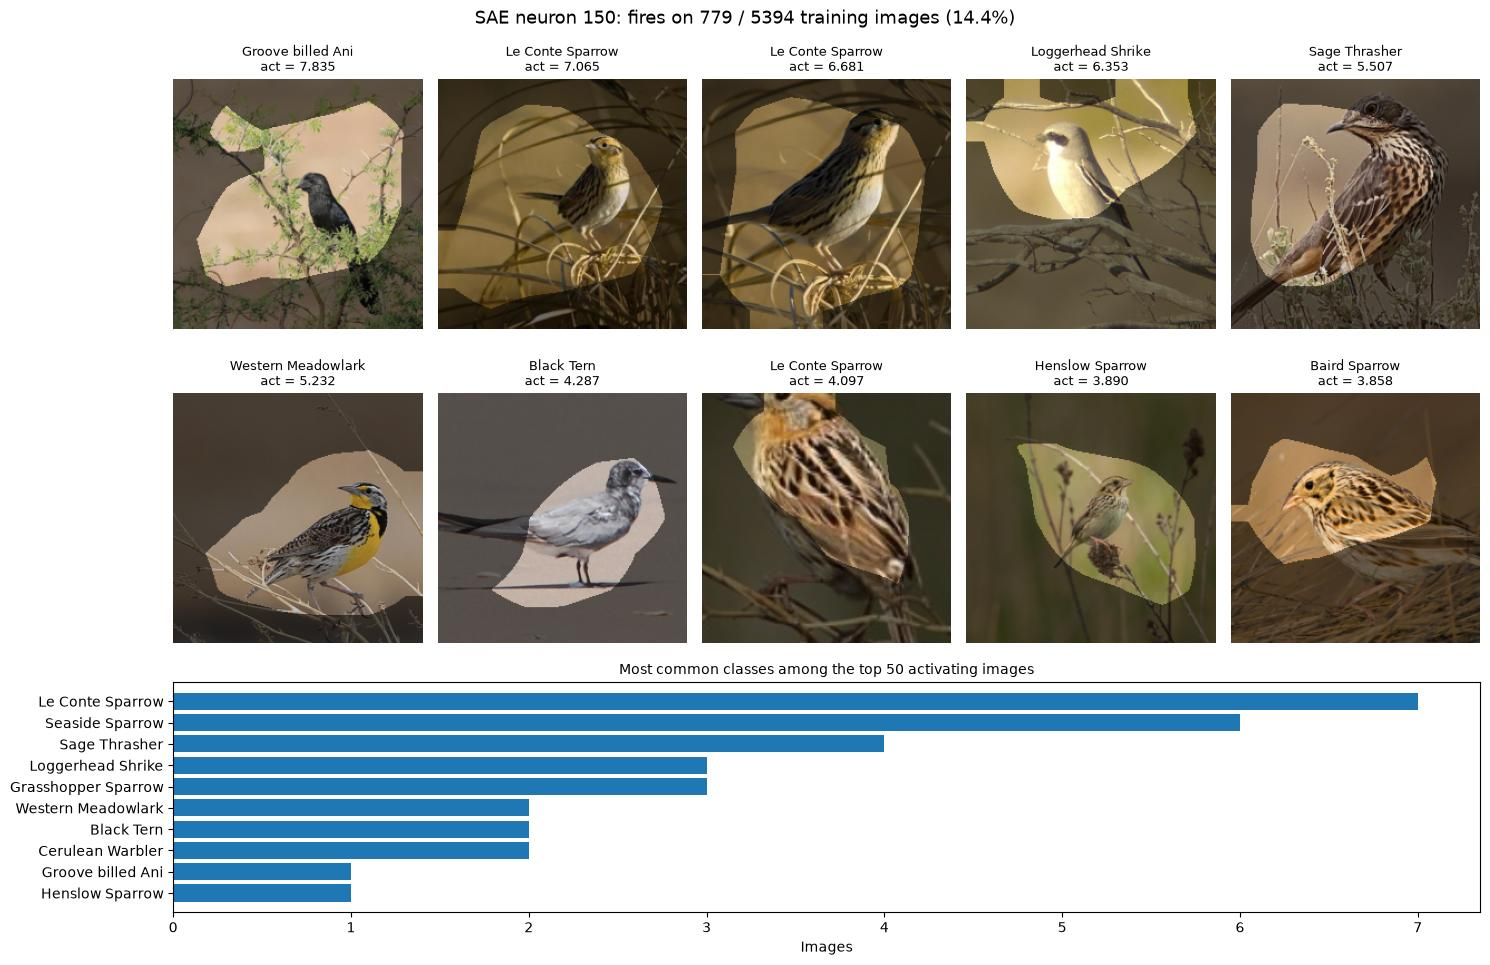

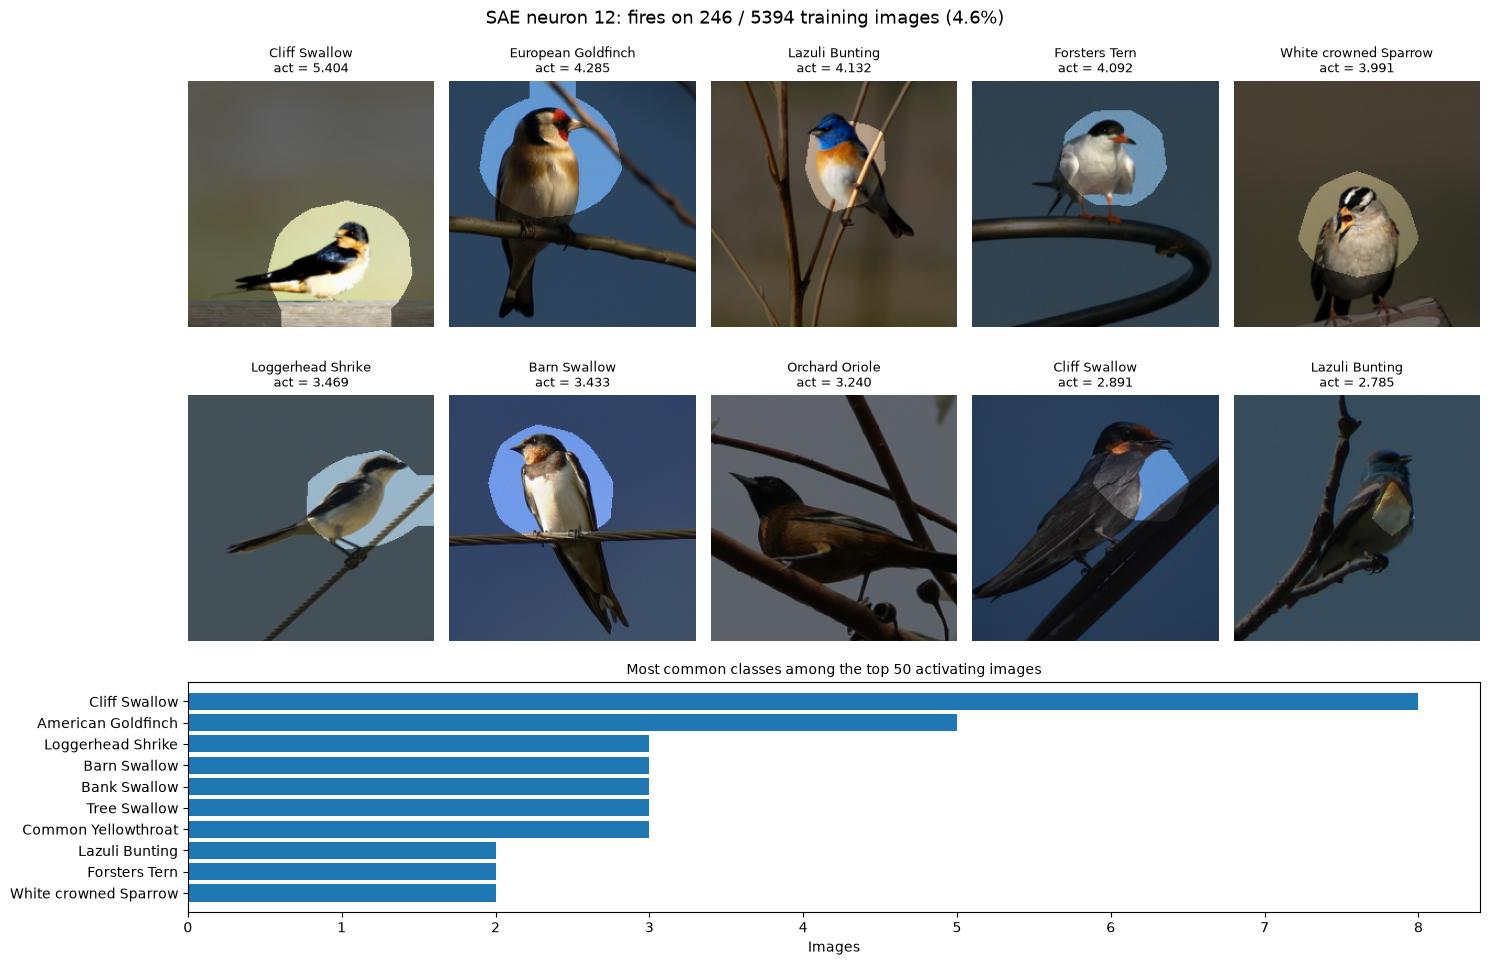

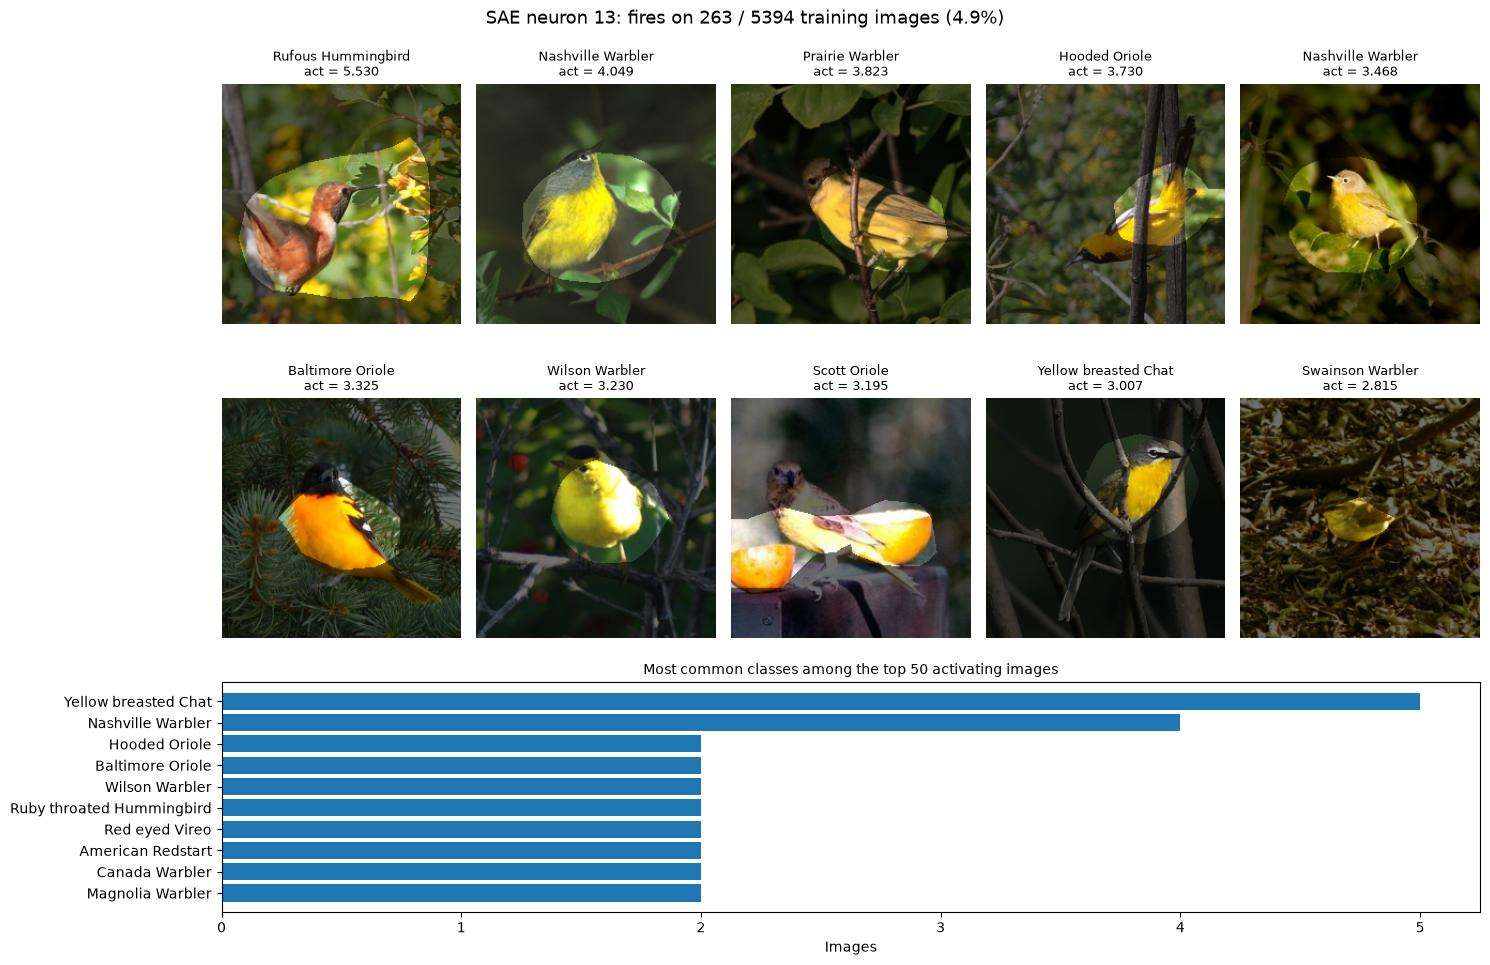

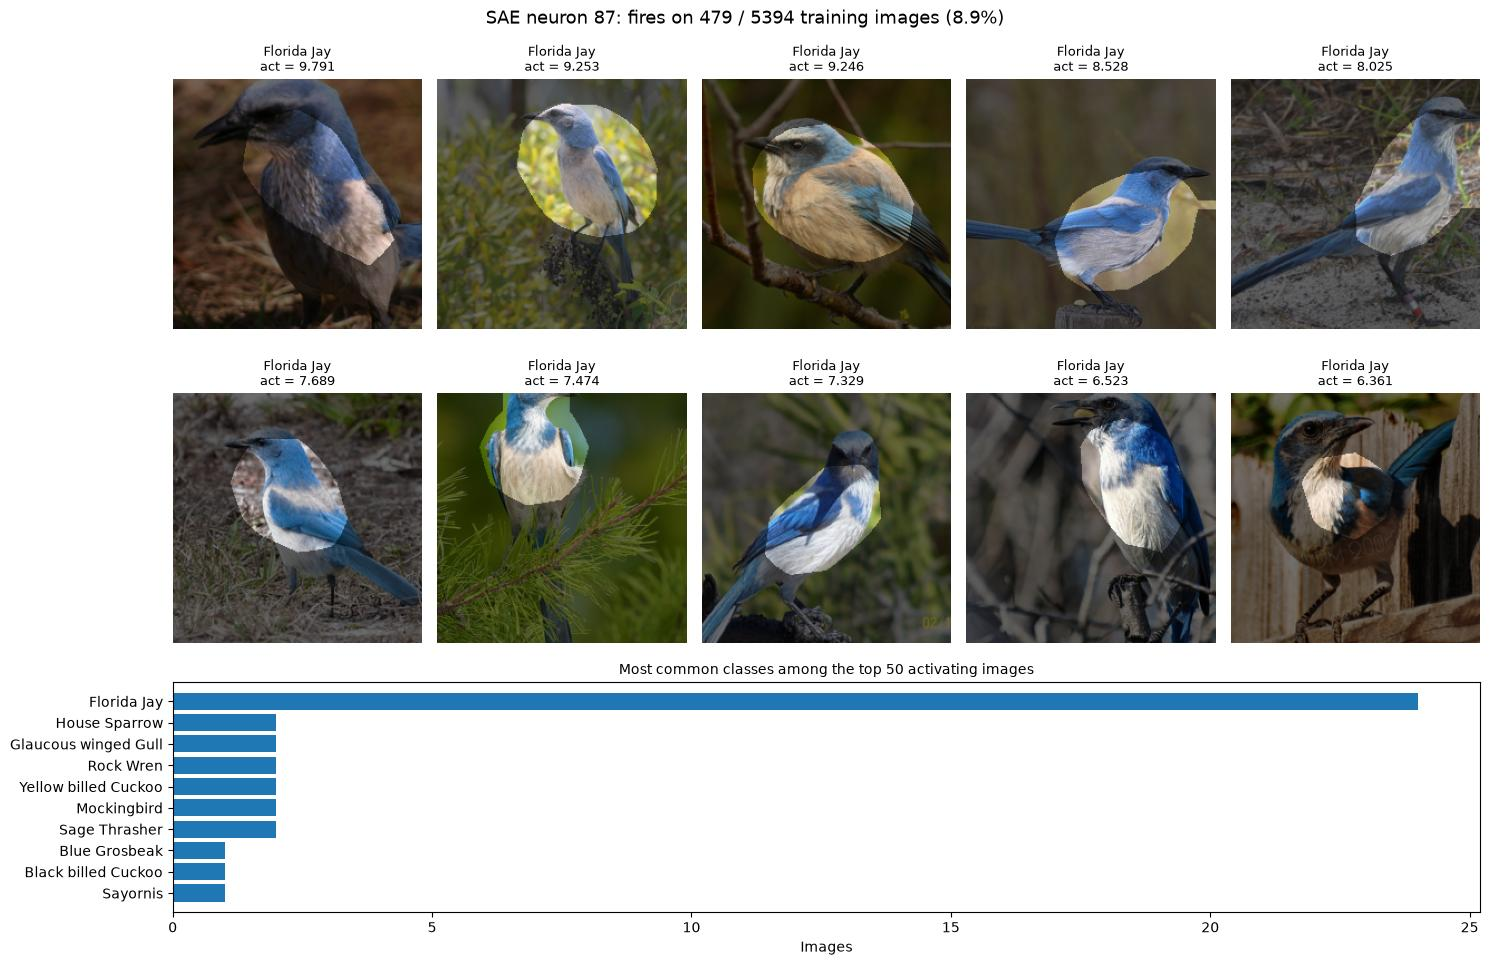

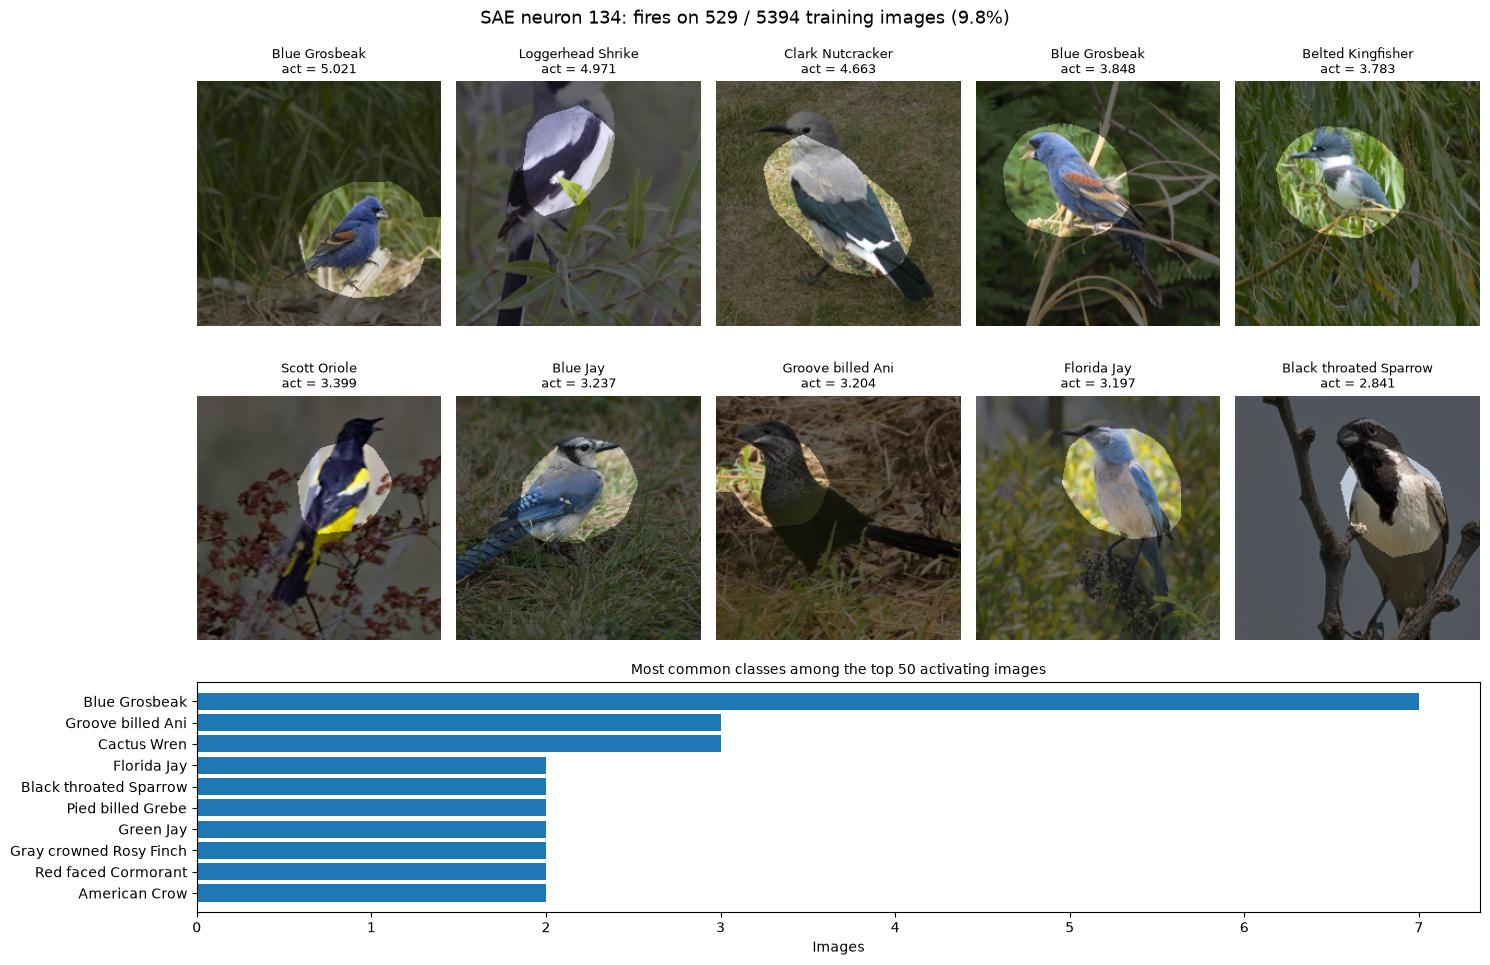

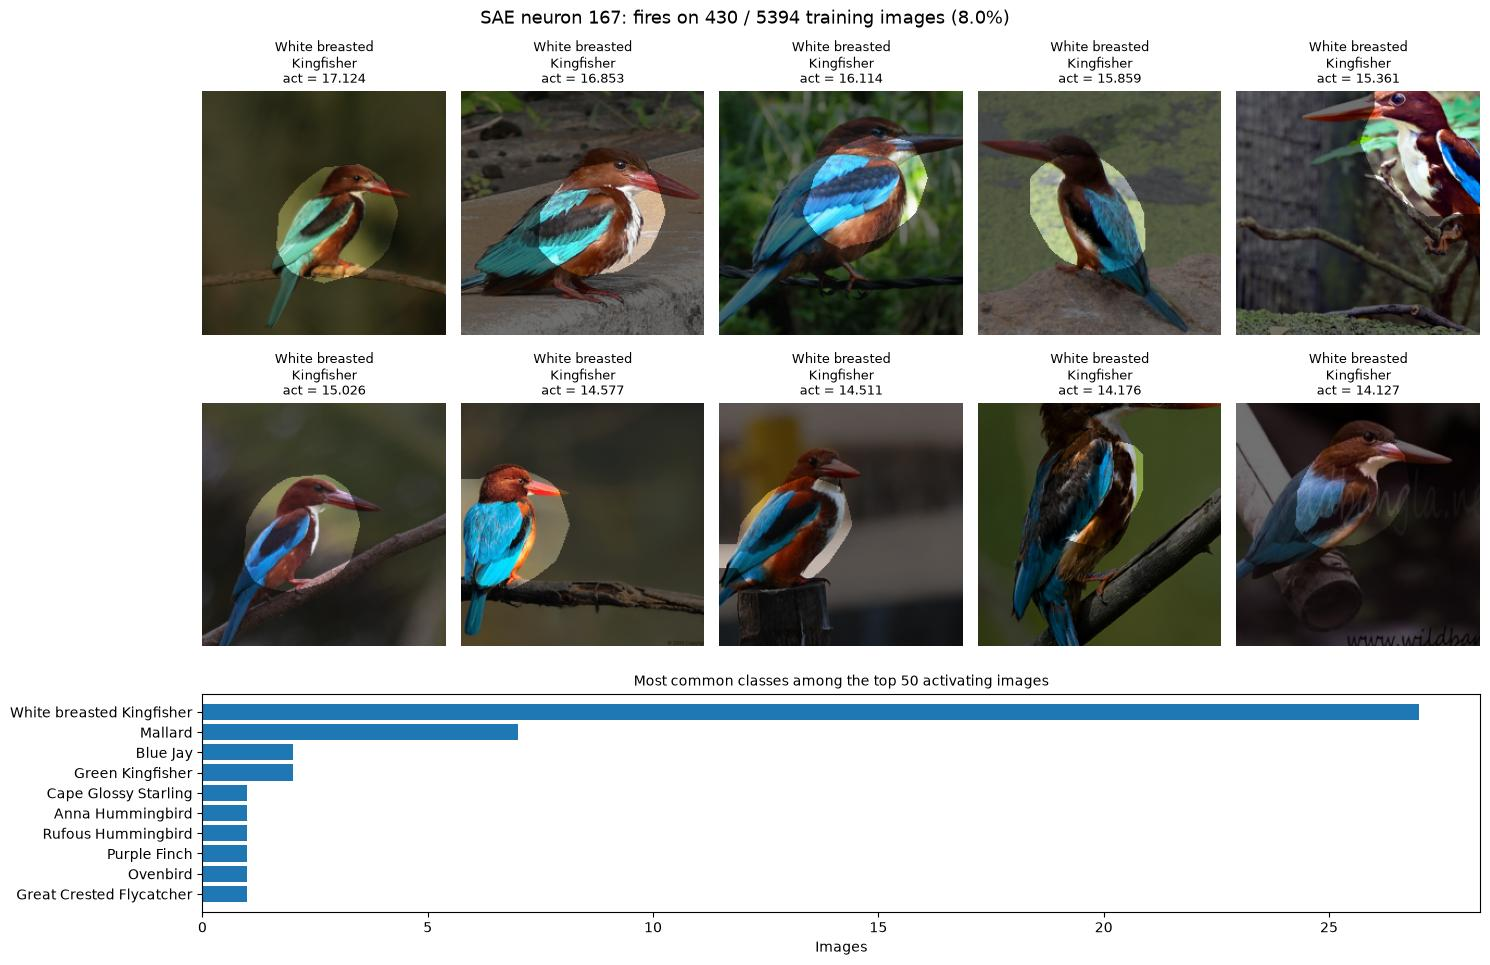

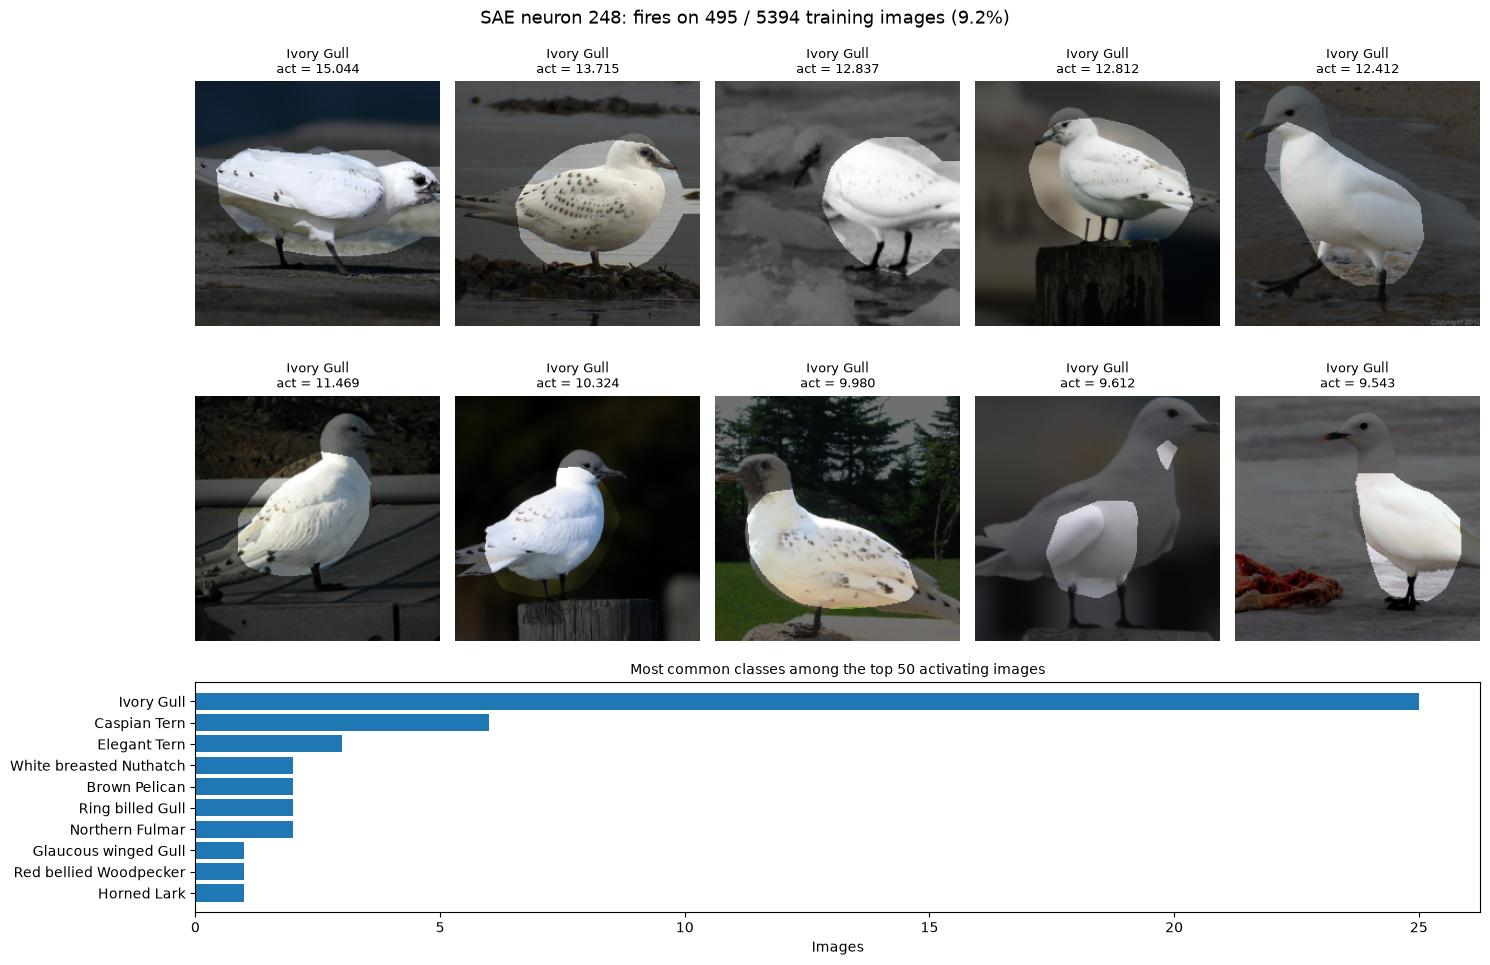

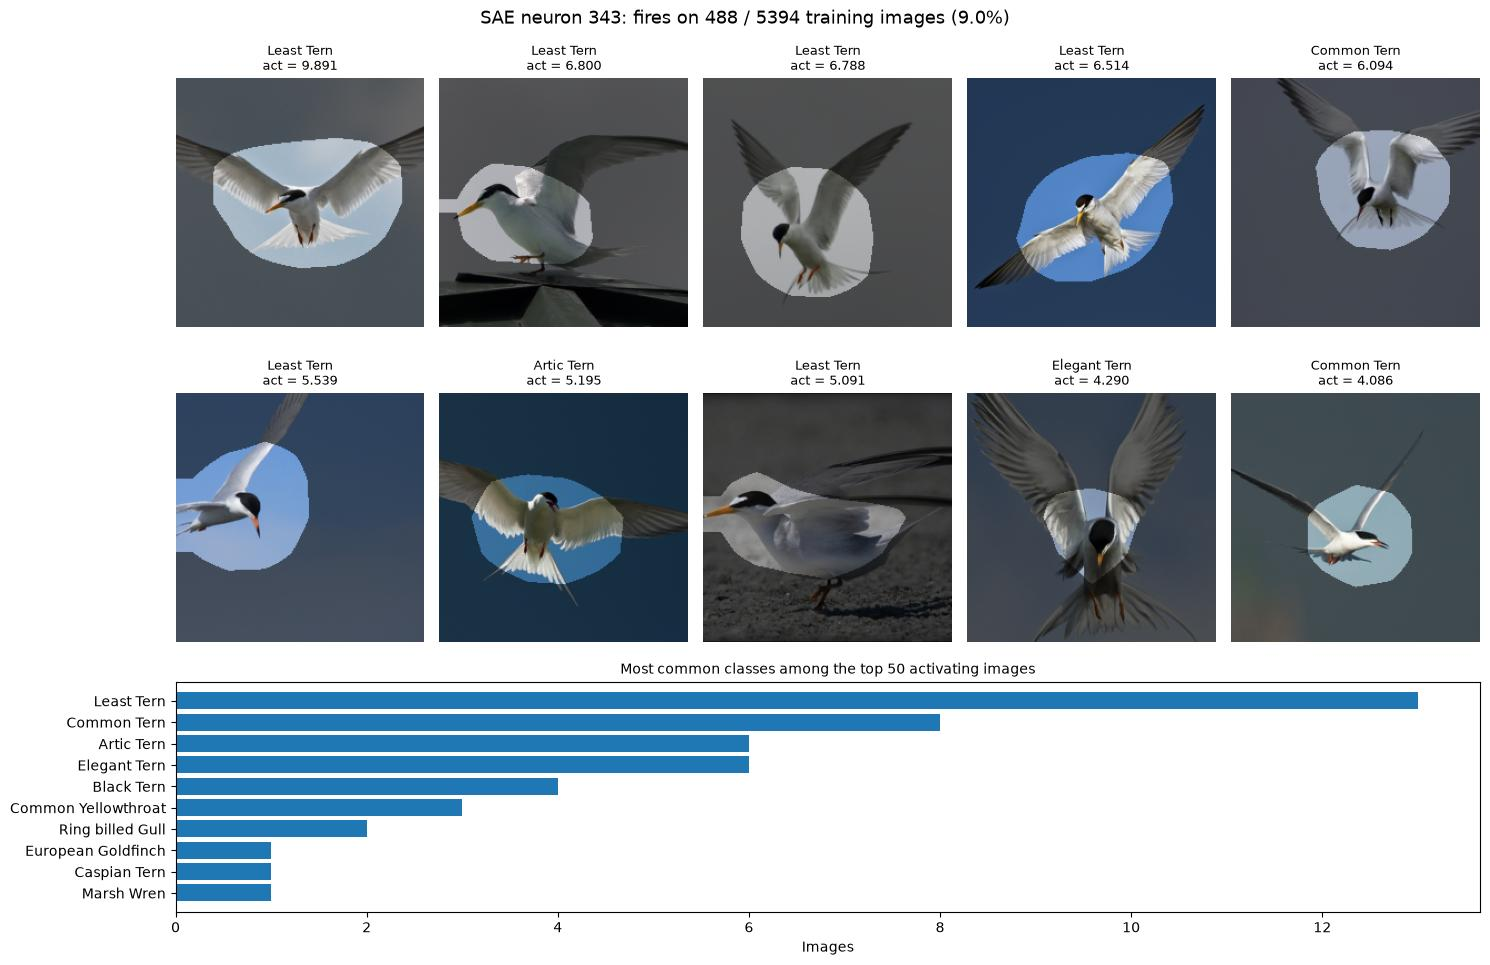

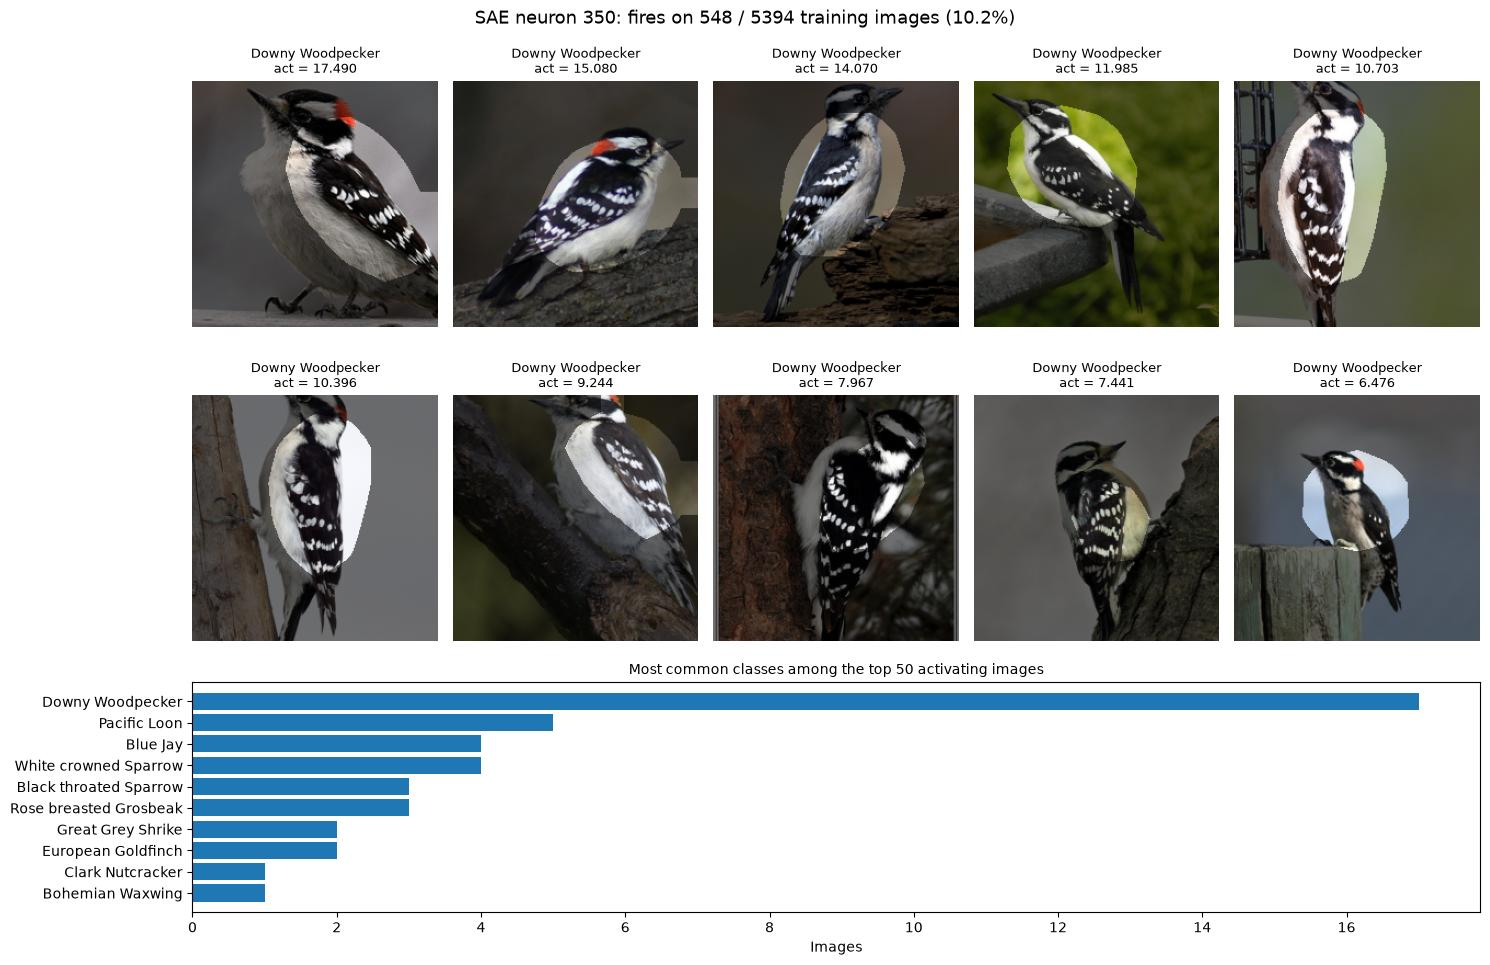

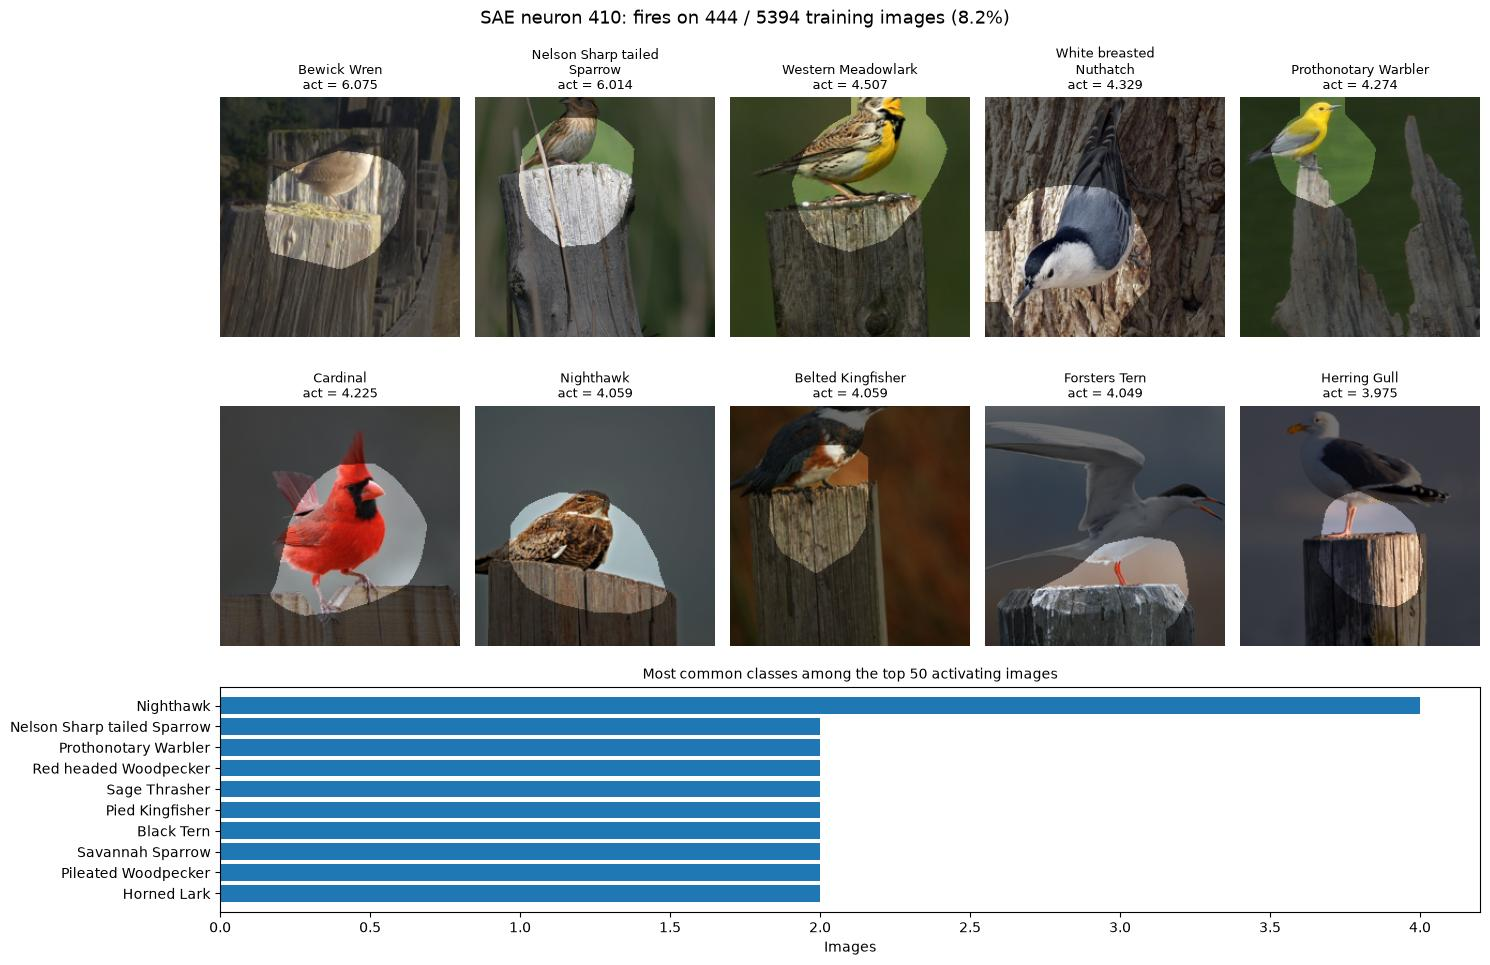

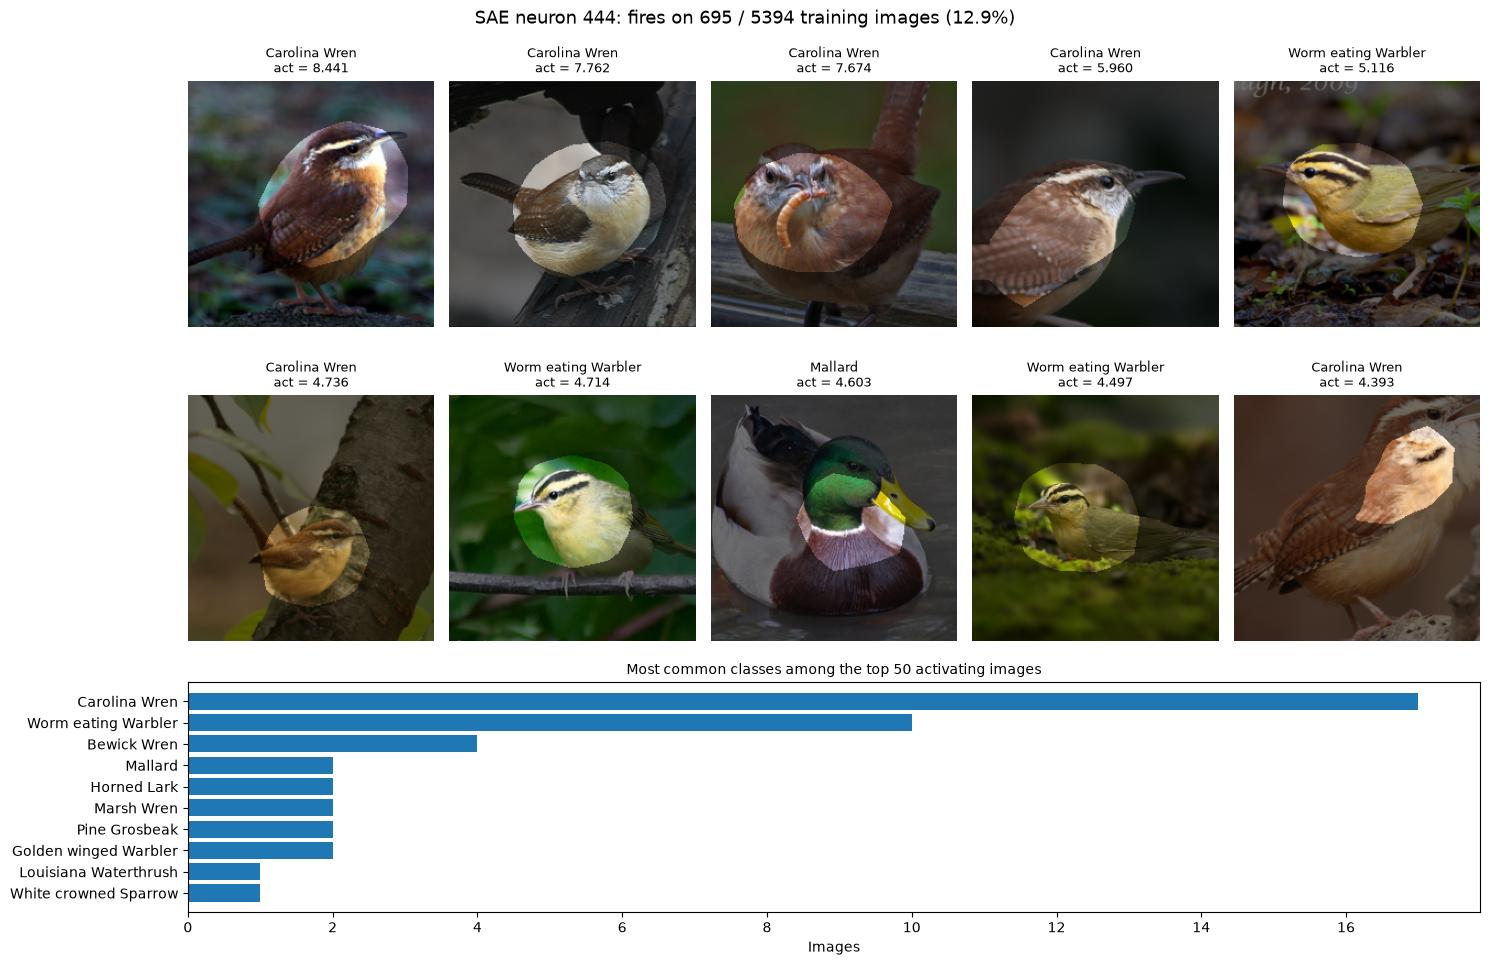

In [5]:
import random

N_NEURONS = 10
N_RANDOM = 10

by_frequency = explorer.neurons_by_frequency()
gallery = by_frequency[:N_NEURONS] + sorted(random.Random(0).sample(by_frequency[N_NEURONS:], min(N_RANDOM, len(by_frequency) - N_NEURONS)))
for neuron in gallery:
    explorer.plot_neuron(neuron, k=10)
    plt.show()